# Amplitude sweeps and critical points, Fig. 1

Storage modulus of GP1–GP5 under a logarithmic oscillatory stress sweep (10 rad/s). The end of the
linear plateau defines the critical stress $\sigma_{cr}$ and the time $t_{cr}$ at which it is reached,
the inputs of eq. (8) (Table 6) and of the composition transfer to GP2–GP4.

* **Input:** `data/amplitude_sweeps_GP1-GP5.xlsx`
* **Output:** `figures/fig01_amplitude_sweeps.png`, `results/critical_points.csv`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rhinn_sindy import data
from rhinn_sindy.paths import RESULTS_DIR
from rhinn_sindy.plotting import save_figure, set_paper_style
from rhinn_sindy.thixotropy import PRESHEAR_S

set_paper_style()
plt.rcParams["lines.markersize"] = 8
MATERIALS = ["GP1", "GP2", "GP3", "GP4", "GP5"]

## Fig. 1

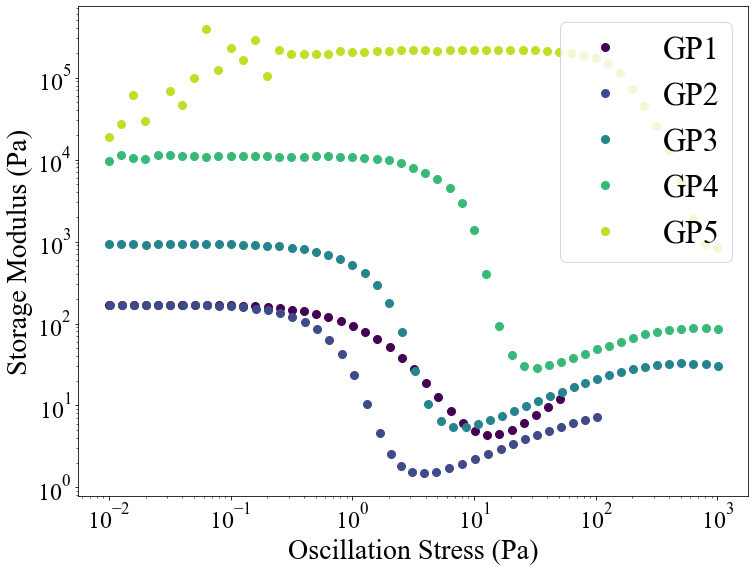

In [2]:
sweeps = {}
for gp in MATERIALS:
    df = data.load_amplitude_sweep(gp)
    df.columns = df.columns.str.strip()
    sweeps[gp] = df

# Viridis up to 0.9 keeps GP5 readable on a white background.
colors = plt.get_cmap("viridis")(np.linspace(0.0, 0.9, len(MATERIALS)))
fig, ax = plt.subplots()
for (gp, df), color in zip(sweeps.items(), colors):
    df = df[df["Storage modulus"] > 0]
    ax.plot(df["Oscillation stress"], df["Storage modulus"], "o", color=color, label=gp)
ax.set(xscale="log", yscale="log", xlabel="Oscillation Stress (Pa)",
       ylabel="Storage Modulus (Pa)")
ax.legend()
save_figure(fig, "fig01_amplitude_sweeps.png")
plt.show()

## Critical points

`TRANSITION_ROW` is the sweep point picked from Fig. 1 as the end of the linear plateau.
The sweep clock includes the 120 s pre-shear, so $t_{cr}$ = Time − 120 s.

`sigma_cr` and `t_cr` are the values used in the paper (rounded readings of that point).
For GP3 the paper value, 870.449 Pa, is the *storage modulus* at the transition row; the
stress there is 0.252 Pa (`stress_at_row`). The paper's Fig. 10 used 870.449 Pa
(see `08c_3ITT_GP2-GP4.ipynb`).

In [3]:
TRANSITION_ROW = {"GP1": 17, "GP2": 13, "GP3": 14, "GP4": 22, "GP5": 43}
PAPER_SIGMA_CR = {"GP1": 0.5, "GP2": 0.2, "GP3": 870.449, "GP4": 1.58505, "GP5": 200.0}
PAPER_T_CR = {"GP1": 717.42, "GP2": 393.0, "GP3": 399.0, "GP4": 449.144, "GP5": 587.52}

rows = []
for gp, row in TRANSITION_ROW.items():
    point = sweeps[gp].iloc[row]
    rows.append({"material": gp, "row": row, "time_s": point["Time"],
                 "stress_at_row": point["Oscillation stress"],
                 "G_prime_at_row": point["Storage modulus"],
                 "t_cr_at_row": point["Time"] - PRESHEAR_S,
                 "sigma_cr": PAPER_SIGMA_CR[gp], "t_cr": PAPER_T_CR[gp]})
critical = pd.DataFrame(rows)
critical.to_csv(RESULTS_DIR / "critical_points.csv", index=False, float_format="%.6g")
critical

,material,row,time_s,stress_at_row,G_prime_at_row,t_cr_at_row,sigma_cr,t_cr
0,GP1,17,837.419,0.506080,130.941,717.419,0.50000,717.420
1,GP2,13,512.634,0.202301,144.536,392.634,0.20000,393.000
2,GP3,14,519.099,0.251782,870.449,399.099,870.44900,399.000
3,GP4,22,569.144,1.585050,10239.800,449.144,1.58505,449.144
4,GP5,43,707.576,199.527000,73284.000,587.576,200.00000,587.520
